# 03 · `gmsEDA` vs NeuroKit2 vs sparsEDA decompositions (no per-subject normalisation)

Notebook 02 showed that `gmsEDA` features (20 chops, overlap 0.9, λ-scale 1) raise LOSO accuracy from 0.837
to 0.875 without per-subject normalisation. **Do standard decompositions do the same?** Two families are compared:
NeuroKit2's filter-based methods and **sparsEDA** (Hernando-Gallego et al., 2018), which, like `gmsEDA`, models
the EDA as a smooth tonic level plus a *sparse* SCR driver convolved with a response kernel.

NeuroKit2 decompositions compared (all on the same 1-min windows, in µS):

| name | NeuroKit2 call | what it does |
|---|---|---|
| `nk_highpass` | `nk.eda_phasic(w, 4, method="highpass")` (**NeuroKit2's default**) | tonic = 2nd-order Butterworth low-pass at 0.05 Hz, phasic = high-pass at 0.05 Hz (zero-phase `sosfiltfilt`) |
| `nk_median` | `nk.eda_phasic(w, 4, method="smoothmedian")` | tonic = 4-s running median (`scipy.signal.medfilt`), phasic = signal − tonic |
| `nk_cvxeda` | `nk.eda_phasic(w, 4, method="cvxeda")` | only if `cvxopt` is installed (see the last section) |
| `sparsEDA` | `nk.eda_phasic(w, 4, method="sparsEDA")` | resample to 8 Hz, non-negative LARS fit of a linear tonic basis + sparse bi-exponential SCR driver |

**Every decomposition is applied to each 1-min window on its own**, exactly like `gmsEDA` in notebook 02. sparsEDA
was designed for longer signals (≥ 80 s); it pads the window internally (20 s before, 60 s after) as in NeuroKit2.

**Implementation note.** The NeuroKit2 methods are run with the real `neurokit2` (version printed below; the
results here used your installed NeuroKit2 0.2.13). `eda_utils` also contains line-for-line copies
(`nk_eda_phasic`, `sparsEDA`) used only as a fallback when `neurokit2` is not installed. The first code cell
checks that the copies give identical output to `nk.eda_phasic`.

**sparsEDA and its driver.** NeuroKit2's `_eda_phasic_sparsEDA` computes the sparse SCR driver but only returns
tonic and phasic. It also **crashes (`IndexError`) on 1-min windows in which no positive driver is found**, in its
driver post-processing step, which runs after tonic and phasic are already computed. sparsEDA is therefore run
with `eda_utils.sparsEDA`, a copy of the NeuroKit2 code that (a) also returns the driver (moved from 8 Hz to the
4 Hz grid by summing impulses) and (b) returns an all-zero driver instead of crashing. Its tonic and phasic are
identical to `nk.eda_phasic(method="sparsEDA")` wherever NeuroKit2 runs (checked in the first cell).

**Features.** Each decomposition goes through the *same* feature function as `gmsEDA` (`gms_signed_features`):
tonic (5), phasic (8) and scale-free ratios. NeuroKit2's filter methods have no sparse driver, so for them the 9
driver features are dropped. `gmsEDA` and `sparsEDA` are shown both **with and without** their driver features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings("ignore")
from eda_utils import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

STRIDE = 10
W = np.load(CACHE / f"windows_stride{STRIDE}.npz")["W"]
meta = pd.read_csv(CACHE / f"windows_meta_stride{STRIDE}.csv")
y, groups = meta.label.values, meta.subject.values

try:
    import neurokit2 as nk
    HAVE_NK = True
    print("neurokit2", nk.__version__, "found")
    chk = range(0, len(W), 25)
    for m in ["highpass", "smoothmedian"]:
        d = max(np.abs(nk.eda_phasic(W[i], sampling_rate=FS, method=m).values - np.c_[nk_eda_phasic(W[i], method=m)]).max() for i in chk)
        print(f"  {m}: max |copy - nk| over {len(chk)} windows = {d:.2e}")
    d, crash = 0.0, 0
    for i in chk:
        try:
            ref = nk.eda_phasic(W[i], sampling_rate=FS, method="sparsEDA")
            d = max(d, np.abs(ref.values - np.c_[sparsEDA(W[i])[:2]]).max())
        except IndexError:
            crash += 1
    print(f"  sparsEDA: max |copy - nk| = {d:.2e}; nk.eda_phasic crashed on {crash} of {len(chk)} windows (no positive driver)")
except ImportError:
    HAVE_NK = False
    print("neurokit2 not installed -> using the copies in eda_utils (nk_eda_phasic, sparsEDA)")

def decompose(w, method):
    if HAVE_NK:
        d = nk.eda_phasic(w, sampling_rate=FS, method=method)
        return d.EDA_Tonic.values, d.EDA_Phasic.values
    return nk_eda_phasic(w, method=method)

neurokit2 0.2.13 found
  highpass: max |copy - nk| over 104 windows = 0.00e+00
  smoothmedian: max |copy - nk| over 104 windows = 0.00e+00
  sparsEDA: max |copy - nk| = 0.00e+00; nk.eda_phasic crashed on 17 of 104 windows (no positive driver)


## 1. NeuroKit2 features for every window

In [2]:
def nk_features(prefix, tonic_phasic_iter):
    rows = []
    for w, (ton, ph) in zip(W, tonic_phasic_iter):
        f = gms_signed_features(w, np.zeros_like(w), ton, ph, prefix=prefix)
        rows.append({k: v for k, v in f.items() if "drv" not in k})     # no driver in NeuroKit2
    return pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).fillna(0.0)

t0 = time.time()
NK = {}
for name, method in [("nk_highpass", "highpass"), ("nk_median", "smoothmedian")]:
    NK[name] = nk_features(name, (decompose(w, method) for w in W))

print(f"{time.time() - t0:.0f}s", {k: v.shape for k, v in NK.items()})

8s {'nk_highpass': (2599, 17), 'nk_median': (2599, 17)}


## 1b. sparsEDA features (each 1-min window)

In [3]:
def sp_features(prefix, W_, T_, P_, D_):
    rows = [gms_signed_features(w, d, ton, ph, prefix=prefix) for w, ton, ph, d in zip(W_, T_, P_, D_)]
    return pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).fillna(0.0)

t0 = time.time()
SP_T, SP_P, SP_D = sparsEDA_windows(W)
SP = {"sparsEDA": sp_features("sparsEDA", W, SP_T, SP_P, SP_D)}
print(f"{time.time() - t0:.0f}s")
print("driver non-zeros per window: %.2f; windows without any driver event: %d of %d"
      % ((SP_D > 0).sum(1).mean(), int(((SP_D > 0).sum(1) == 0).sum()), len(W)))

34s
driver non-zeros per window: 2.40; windows without any driver event: 420 of 2599


### What the decompositions look like (same windows as in notebook 02)
Black = EDA, orange = tonic, green = phasic (right axis), red = sparse driver (right axis).

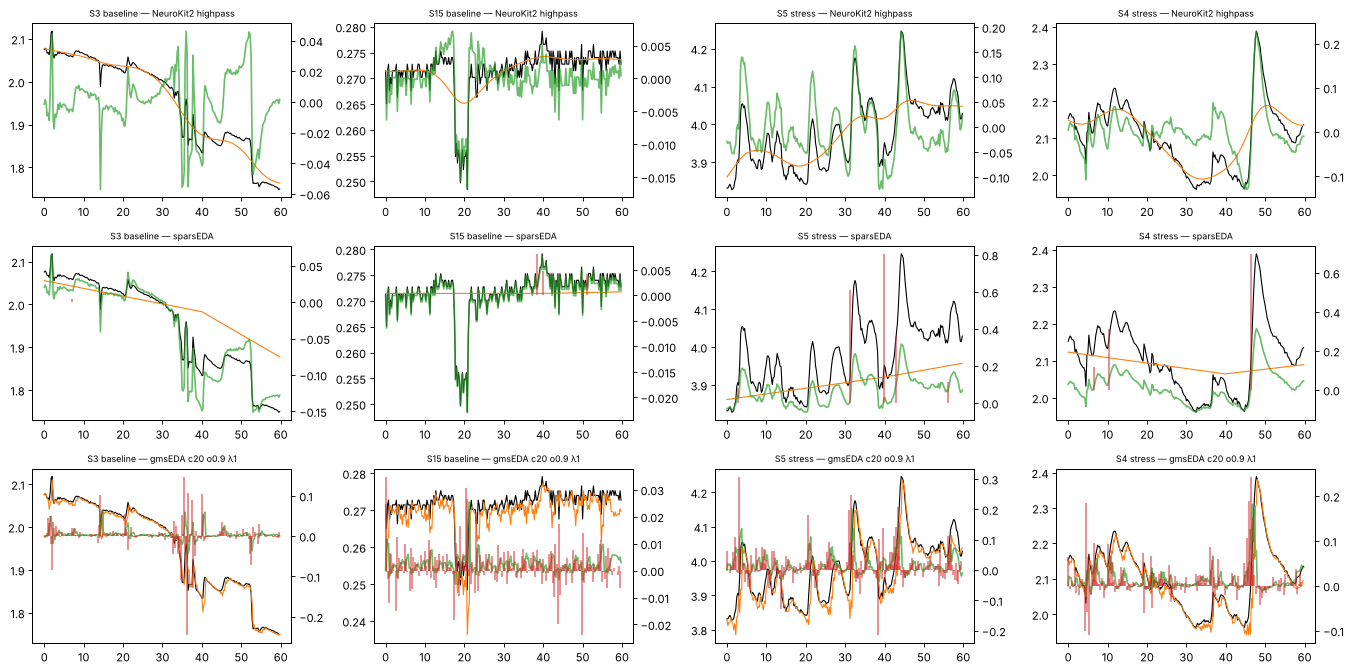

In [4]:
rng = np.random.default_rng(3)
idx = list(rng.choice(np.flatnonzero(y == 1), 2, replace=False)) + list(rng.choice(np.flatnonzero(y == 2), 2, replace=False))
t = np.arange(WIN) / FS
fig, axes = plt.subplots(3, 4, figsize=(17, 8.5))
for col, i in enumerate(idx):
    s, st = meta.subject[i], meta.start[i]
    g = gmsEDA_window(W[i], 20, 0.9, 1, 0)
    comps = [("NeuroKit2 highpass", decompose(W[i], "highpass"), None),
             ("sparsEDA", (SP_T[i], SP_P[i]), SP_D[i]),
             ("gmsEDA c20 o0.9 λ1", (g[1], g[2]), g[0])]
    for row, (title, (ton, ph), drv) in enumerate(comps):
        ax = axes[row, col]
        ax.plot(t, W[i], "k", lw=1); ax.plot(t, ton, color="tab:orange", lw=1)
        ax2 = ax.twinx(); ax2.plot(t, ph, color="tab:green", alpha=.7)
        if drv is not None:
            ax2.vlines(t, 0, drv, color="tab:red", alpha=.6)
        ax.set_title(f"{s} {'stress' if y[i] == 2 else 'baseline'} — {title}", fontsize=8)
plt.tight_layout(); plt.show()

## 2. LOSO comparison (4 classifiers)

In [5]:
R = pd.read_csv(CACHE / "rawfeat_abs.csv")
RAW = R[[c for c in R if not c.startswith("rel_")]]
BEST = "c20_o0.9_l1_nn0"
GMS = gms_config_features(W, dict(num_of_chops=20, overlap=0.9, lam_scale=1, force_nn=0))
GMS_NODRV = GMS[[c for c in GMS if "drv" not in c]]
print("feature counts:", {"raw": RAW.shape[1], "gms": GMS.shape[1], "gms w/o driver": GMS_NODRV.shape[1],
                          **{k: v.shape[1] for k, v in NK.items()}, **{k: v.shape[1] for k, v in SP.items()}})

SETS = {"raw": RAW}
for k, v in NK.items():
    SETS[f"raw + {k}"] = pd.concat([RAW, v], axis=1)
for k, v in SP.items():
    SETS[f"raw + {k} (tonic/phasic only)"] = pd.concat([RAW, v[[c for c in v if "drv" not in c]]], axis=1)
    SETS[f"raw + {k} (full)"] = pd.concat([RAW, v], axis=1)
SETS["raw + gmsEDA (tonic/phasic only)"] = pd.concat([RAW, GMS_NODRV], axis=1)
SETS["raw + gmsEDA (full)"] = pd.concat([RAW, GMS], axis=1)
for k, v in NK.items():
    SETS[f"{k} alone"] = v
for k, v in SP.items():
    SETS[f"{k} (full) alone"] = v
SETS["gmsEDA (full) alone"] = GMS

t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups)
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

feature counts: {'raw': 33, 'gms': 28, 'gms w/o driver': 17, 'nk_highpass': 17, 'nk_median': 17, 'sparsEDA': 28}
289s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.840,0.831,0.824,0.853,0.837
raw + nk_highpass,0.848,0.836,0.845,0.860,0.847
raw + nk_median,0.850,0.832,0.841,0.866,0.847
raw + sparsEDA (tonic/phasic only),0.845,0.831,0.848,0.851,0.844
raw + sparsEDA (full),0.846,0.834,0.845,0.856,0.845
raw + gmsEDA (tonic/phasic only),0.851,0.847,0.857,0.878,0.858
raw + gmsEDA (full),0.870,0.869,0.868,0.895,0.875
nk_highpass alone,0.802,0.795,0.836,0.835,0.817
nk_median alone,0.817,0.783,0.840,0.843,0.821


In [6]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.821,0.807,0.805,0.830,0.816
raw + nk_highpass,0.830,0.811,0.826,0.841,0.827
raw + nk_median,0.833,0.807,0.825,0.847,0.828
raw + sparsEDA (tonic/phasic only),0.828,0.804,0.832,0.830,0.823
raw + sparsEDA (full),0.829,0.809,0.828,0.836,0.826
raw + gmsEDA (tonic/phasic only),0.834,0.826,0.842,0.862,0.841
raw + gmsEDA (full),0.854,0.851,0.854,0.881,0.860
nk_highpass alone,0.784,0.759,0.818,0.812,0.793
nk_median alone,0.798,0.740,0.823,0.820,0.795


### Paired per-subject test against `raw`
Each cell gives Δ mean subject accuracy (subjects improved / worse, Wilcoxon p).

In [7]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw + nk_highpass,"+0.008 (7/5, p=0.272)","+0.004 (7/5, p=0.754)","+0.021 (9/5, p=0.221)","+0.008 (9/3, p=0.050)"
raw + nk_median,"+0.011 (6/5, p=0.286)","+0.001 (7/7, p=0.826)","+0.017 (9/3, p=0.182)","+0.013 (10/3, p=0.033)"
raw + sparsEDA (tonic/phasic only),"+0.005 (7/4, p=0.398)","-0.001 (7/6, p=0.727)","+0.024 (11/2, p=0.028)","-0.002 (5/8, p=0.650)"
raw + sparsEDA (full),"+0.006 (10/2, p=0.084)","+0.003 (9/5, p=0.594)","+0.020 (11/2, p=0.025)","+0.003 (6/8, p=0.754)"
raw + gmsEDA (tonic/phasic only),"+0.012 (9/5, p=0.140)","+0.016 (8/4, p=0.224)","+0.034 (11/3, p=0.026)","+0.026 (12/2, p=0.004)"
raw + gmsEDA (full),"+0.031 (11/3, p=0.096)","+0.038 (10/4, p=0.019)","+0.045 (12/1, p=0.019)","+0.042 (12/1, p=0.002)"
nk_highpass alone,"-0.038 (4/9, p=0.133)","-0.037 (4/11, p=0.053)","+0.012 (6/8, p=0.778)","-0.018 (4/10, p=0.158)"
nk_median alone,"-0.023 (5/9, p=0.221)","-0.050 (6/9, p=0.074)","+0.015 (10/4, p=0.272)","-0.009 (4/11, p=0.211)"
sparsEDA (full) alone,"-0.028 (4/9, p=0.173)","-0.044 (5/10, p=0.057)","+0.028 (9/5, p=0.158)","-0.032 (4/11, p=0.099)"


### Head-to-head: `raw + gmsEDA` vs `raw + NeuroKit2 highpass`

In [8]:
_, h2h = compare_feature_sets({"raw + nk_highpass": SETS["raw + nk_highpass"],
                               "raw + gmsEDA (full)": SETS["raw + gmsEDA (full)"],
                               "raw + gmsEDA (tonic/phasic only)": SETS["raw + gmsEDA (tonic/phasic only)"]},
                              y, groups, baseline="raw + nk_highpass")
h2h.round(3)

,features,model,delta,wins,losses,p
0,raw + gmsEDA (full),LogReg,0.033,10,4,0.035
1,raw + gmsEDA (full),SVM-RBF,0.034,10,1,0.004
2,raw + gmsEDA (full),RandomForest,0.024,10,3,0.055
3,raw + gmsEDA (full),HistGB,0.023,11,3,0.158
4,raw + gmsEDA (tonic/phasic only),LogReg,0.012,10,3,0.249
5,raw + gmsEDA (tonic/phasic only),SVM-RBF,0.018,12,1,0.016
6,raw + gmsEDA (tonic/phasic only),RandomForest,0.013,9,4,0.221
7,raw + gmsEDA (tonic/phasic only),HistGB,0.004,9,5,0.470


### Head-to-head: `raw + gmsEDA` vs the best sparsEDA variant

In [9]:
sp_best = max([k for k in SETS if k.startswith("raw + sparsEDA")], key=lambda k: acc.loc[k, "mean"])
print("best sparsEDA variant:", sp_best)
_, h2h_sp = compare_feature_sets({sp_best: SETS[sp_best], "raw + gmsEDA (full)": SETS["raw + gmsEDA (full)"]},
                                 y, groups, baseline=sp_best)
h2h_sp.round(3)

best sparsEDA variant: raw + sparsEDA (full)


,features,model,delta,wins,losses,p
0,raw + gmsEDA (full),LogReg,0.035,12,3,0.021
1,raw + gmsEDA (full),SVM-RBF,0.039,13,1,0.001
2,raw + gmsEDA (full),RandomForest,0.025,11,2,0.033
3,raw + gmsEDA (full),HistGB,0.025,11,3,0.124


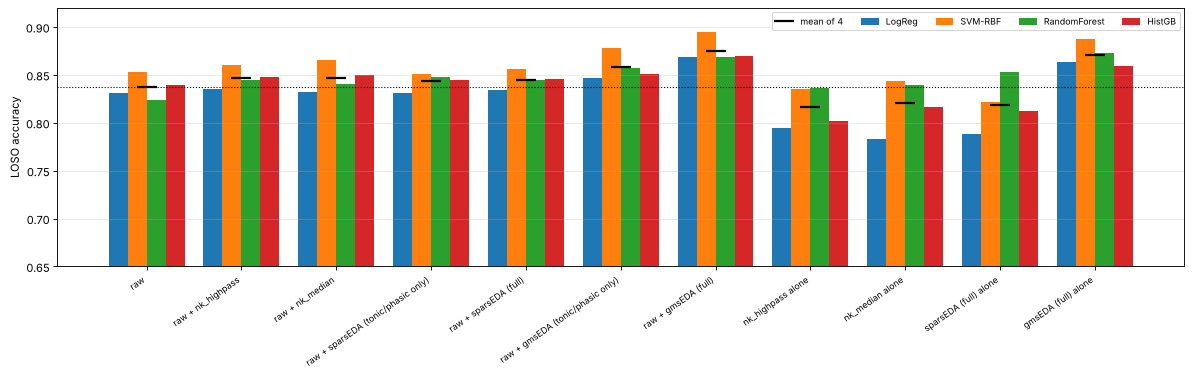

In [10]:
fig, ax = plt.subplots(figsize=(15, 4.8))
order = list(SETS)
xs = np.arange(len(order))
for j, m in enumerate(["LogReg", "SVM-RBF", "RandomForest", "HistGB"]):
    ax.bar(xs + (j - 1.5) * 0.2, acc.loc[order, m].values, width=0.2, label=m)
ax.plot(xs, acc.loc[order, "mean"].values, "k_", ms=18, mew=2, label="mean of 4")
ax.axhline(acc.loc["raw", "mean"], color="k", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=35, ha="right", fontsize=8)
ax.set_ylim(0.65, 0.92); ax.set_ylabel("LOSO accuracy"); ax.legend(fontsize=8, ncol=5); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 3. Optional: NeuroKit2 cvxEDA
Runs only when `neurokit2` **and** `cvxopt` are installed (not available where this notebook was executed).
cvxEDA solves a convex QP per window, so this takes a few minutes.

In [11]:
try:
    import cvxopt  # noqa: F401
    assert HAVE_NK
    t0 = time.time()
    NK["nk_cvxeda"] = nk_features("nk_cvxeda", (decompose(w, "cvxeda") for w in W))
    r_cvx, p_cvx = compare_feature_sets({"raw": RAW, "raw + nk_cvxeda": pd.concat([RAW, NK["nk_cvxeda"]], axis=1)}, y, groups)
    print(f"{time.time() - t0:.0f}s")
    display(r_cvx.pivot(index="features", columns="model", values="acc").round(3))
    display(p_cvx.round(3))
except (ImportError, AssertionError):
    print("cvxopt / neurokit2 not installed - cvxEDA skipped")

cvxopt / neurokit2 not installed - cvxEDA skipped


## Conclusion

All decompositions are applied to each 1-min window on its own. NeuroKit2 0.2.13 (the installed version) was used
for the NeuroKit2 methods. The copies in `eda_utils` give identical output (max difference 0).

**Neither NeuroKit2's filter methods nor sparsEDA come close to `gmsEDA`.** Mean LOSO accuracy over the 4
classifiers (no per-subject normalisation):

| features | mean acc | Δ vs raw |
|---|---|---|
| raw | 0.837 | – |
| raw + NeuroKit2 highpass (default) | 0.847 | +0.010 |
| raw + NeuroKit2 smoothmedian | 0.847 | +0.010 |
| raw + sparsEDA, tonic/phasic only (what NeuroKit2 returns) | 0.844 | +0.007 |
| raw + sparsEDA, with its driver | 0.845 | +0.008 |
| raw + gmsEDA, tonic/phasic only | 0.858 | +0.021 |
| **raw + gmsEDA (full)** | **0.875** | **+0.038** |

* **sparsEDA** adds under 1 point. Only RandomForest gains significantly (+0.02, p ≈ 0.03), and LogReg and SVM do
  not gain at all. On their own, sparsEDA features (0.819) are worse than the raw features.
* On 1-min windows sparsEDA finds 2.4 driver events per window on average, and **none in 420 of 2,599 windows**.
  On those windows `nk.eda_phasic(method="sparsEDA")` raises an `IndexError` (17 of 104 checked windows). The copy
  used here returns an all-zero driver instead, with the same tonic and phasic. Its tonic is a piecewise-linear trend,
  so the phasic part absorbs most of the within-minute variation (see the figure).
* Head-to-head, `raw + gmsEDA` beats `raw + sparsEDA` by **+2.5 to +3.9 points** (11–13 of 15 subjects better;
  p = 0.001 SVM, 0.021 LogReg, 0.033 RF, 0.12 HistGB). Against NeuroKit2 highpass the margin is +2.3 to +3.4.
* So the benefit is specific to `gmsEDA` with short, highly overlapping chops and λ ≈ 1. Its dense signed driver
  (counts of fast rises and falls) is the main source of the gain: even without the driver, `gmsEDA` is ahead of both
  alternatives (0.858 vs 0.844–0.847).
* Not tested: NeuroKit2's cvxEDA (needs `cvxopt`; section 3 runs it automatically when available) and NeuroKit2's
  SCR-peak features (`eda_peaks`).